# 1) mount drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2) import libraries

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from scipy.stats import boxcox
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

%matplotlib inline

# 3) read dataset

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ML/ML/تمرین دوم/Data/heart.csv')
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


# 4) preprocess data

In [ ]:
# Display a concise summary of the dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [ ]:
# Define the continuous features
continuous_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# Identify the features to be converted to object data type
features_to_convert = [feature for feature in df.columns if feature not in continuous_features]

# Convert the identified features to object data type
df[features_to_convert] = df[features_to_convert].astype('object')

df.dtypes

,0
age,int64
sex,object
cp,object
trestbps,int64
chol,int64
fbs,object
restecg,object
thalach,int64
exang,object
oldpeak,float64


In [ ]:
# Get the summary statistics for numerical variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [ ]:
# Get the summary statistics for categorical variables
df.describe(include='object')

,sex,cp,fbs,restecg,exang,slope,ca,thal,target
count,303,303,303,303,303,303,303,303,303
unique,2,4,2,3,2,3,5,4,2
top,1,0,0,1,0,2,0,2,1
freq,207,143,258,152,204,142,175,166,165


In [ ]:
# Check for missing values in the dataset
df.isnull().sum().sum()

np.int64(0)

In [ ]:
continuous_features

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

In [ ]:
# check for outliers using the IQR method for the continuous features
Q1 = df[continuous_features].quantile(0.25)
Q3 = df[continuous_features].quantile(0.75)
IQR = Q3 - Q1
outliers_count_specified = ((df[continuous_features] < (Q1 - 1.5 * IQR)) | (df[continuous_features] > (Q3 + 1.5 * IQR))).sum()

outliers_count_specified

,0
age,0
trestbps,9
chol,5
thalach,1
oldpeak,5


In [ ]:
# Categorical Features Encoding
# Implementing one-hot encoding on the specified categorical features
df_encoded = pd.get_dummies(df, columns=['cp', 'restecg', 'thal'], drop_first=True)

# Convert the rest of the categorical variables that don't need one-hot encoding to integer data type
features_to_convert = ['sex', 'fbs', 'exang', 'slope', 'ca', 'target']
for feature in features_to_convert:
    df_encoded[feature] = df_encoded[feature].astype(int)

df_encoded.dtypes

,0
age,int64
sex,int64
trestbps,int64
chol,int64
fbs,int64
thalach,int64
exang,int64
oldpeak,float64
slope,int64
ca,int64


In [ ]:
# Displaying the resulting DataFrame after one-hot encoding
df_encoded.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,slope,ca,target,cp_1,cp_2,cp_3,restecg_1,restecg_2,thal_1,thal_2,thal_3
0,63,1,145,233,1,150,0,2.3,0,0,1,False,False,True,False,False,True,False,False
1,37,1,130,250,0,187,0,3.5,0,0,1,False,True,False,True,False,False,True,False
2,41,0,130,204,0,172,0,1.4,2,0,1,True,False,False,False,False,False,True,False
3,56,1,120,236,0,178,0,0.8,2,0,1,True,False,False,True,False,False,True,False
4,57,0,120,354,0,163,1,0.6,2,0,1,False,False,False,True,False,False,True,False


In [ ]:
# Define the features (X) and the output labels (y)
X = df_encoded.drop('target', axis=1)
y = df_encoded['target']

In [ ]:
# Splitting data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

In [ ]:
continuous_features

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

In [ ]:
X_train.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,slope,ca,cp_1,cp_2,cp_3,restecg_1,restecg_2,thal_1,thal_2,thal_3
269,56,1,130,283,1,103,1,1.6,0,0,False,False,False,False,False,False,False,True
191,58,1,128,216,0,131,1,2.2,1,3,False,False,False,False,False,False,False,True
15,50,0,120,219,0,158,0,1.6,1,0,False,True,False,True,False,False,True,False
224,54,1,110,239,0,126,1,2.8,1,1,False,False,False,True,False,False,False,True
250,51,1,140,298,0,122,1,4.2,1,3,False,False,False,True,False,False,False,True


In [ ]:
scaler = StandardScaler()

X_train[continuous_features] = scaler.fit_transform(X_train[continuous_features])
X_test[continuous_features] = scaler.transform(X_test[continuous_features])

# 5) Scratch LR Model (my class for LR)

In [ ]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.01, iterations=1000, threshold=0.5):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = 0
        self.cost_history = []
        self.threshold = threshold

    def sigmoid(self, z):
        """Sigmoid activation function"""
        return 1 / (1 + np.exp(-z))

    def compute_loss(self, h, y):
        """Cross-entropy loss"""
        m = len(y)
        return - (1/m) * np.sum(y*np.log(h) + (1-y)*np.log(1-h))

    def gradient_descent(self, X, y):
        """Compute gradients for gradient descent"""
        z = np.dot(X, self.weights) + self.bias
        h = self.sigmoid(z)
        m = len(y)
        dw = (1/m) * np.dot(X.T, (h - y))
        db = (1/m) * np.sum(h - y)

        self.weights -= self.lr * dw
        self.bias -= self.lr * db


    def fit(self, X, y):
        """Train model using gradient descent"""
        m, n = X.shape
        self.weights = np.zeros(n)

        for _ in range(self.iterations):
            z = np.dot(X, self.weights) + self.bias
            h = self.sigmoid(z)
            self.gradient_descent(X, y)
            self.cost_history.append(self.compute_loss(h, y))

    def predict(self, X):
        """Make predictions"""
        return (self.sigmoid(np.dot(X, self.weights) + self.bias) >= self.threshold).astype(int)

In [ ]:
# Train our logistic regression model
model = LogisticRegressionScratch(learning_rate=0.1, iterations=1000)
model.fit(X_train.astype(float), y_train.astype(float))

# Evaluate accuracy
predictions = model.predict(X_test.astype(float))
accuracy = np.mean(predictions == y_test.astype(float))
print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.84


In [ ]:
class_report = classification_report(y_test, predictions)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.79      0.81        28
           1       0.83      0.88      0.85        33

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
conf_matrix = confusion_matrix(y_test, predictions)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[22  6]
 [ 4 29]]


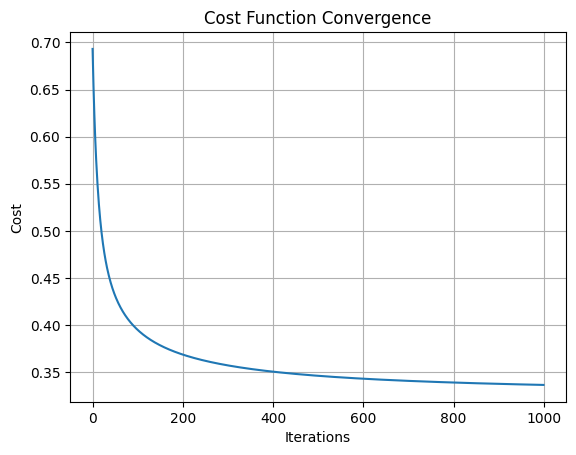

In [ ]:
plt.plot(model.cost_history)
plt.title("Cost Function Convergence")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.grid(True)
plt.show()

In [ ]:
y_probs = model.sigmoid(np.dot(X_test.astype(float), model.weights) + model.bias)

roc_auc = roc_auc_score(y_test, y_probs)
roc_auc

np.float64(0.8917748917748918)

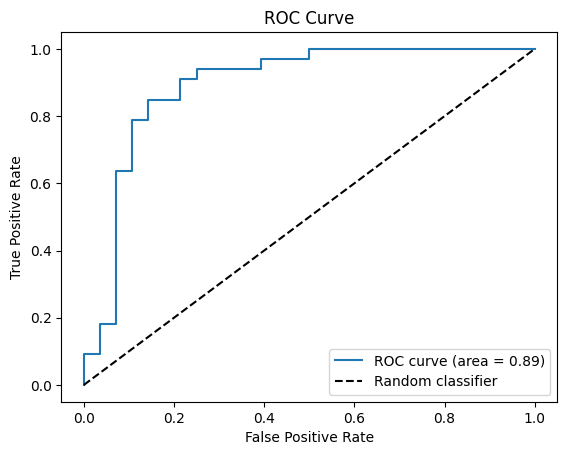

In [ ]:
# Compute the false positive rate (FPR)
# and true positive rate (TPR) for different classification thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_probs, pos_label=1)

# Plot the ROC curve
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
# roc curve for tpr = fpr
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

## optimum threshold

In [ ]:
threshold = np.arange(0, 1, 0.1)

# obtain probabilities
probs =(model.sigmoid(np.dot(X_test.astype(float), model.weights) + model.bias))

accuracy_list = []
for thresh in threshold:

  # obtain class prediction based on threshold
  predictions = np.where(probs>=thresh, 1, 0)

  #predictions = model.predict(X_test.astype(float))
  accuracy = np.mean(predictions == y_test.astype(float))
  accuracy_list.append(accuracy)
  print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.54
Model Accuracy: 0.79
Model Accuracy: 0.82
Model Accuracy: 0.84
Model Accuracy: 0.85
Model Accuracy: 0.84
Model Accuracy: 0.84
Model Accuracy: 0.84
Model Accuracy: 0.77
Model Accuracy: 0.67


In [ ]:
best_index = np.argmax(accuracy_list)
best_threshold = threshold[best_index]

print('best threshold: ', best_threshold)
print('best accuracy: ', accuracy_list[best_index])

best threshold:  0.4
best accuracy:  0.8524590163934426


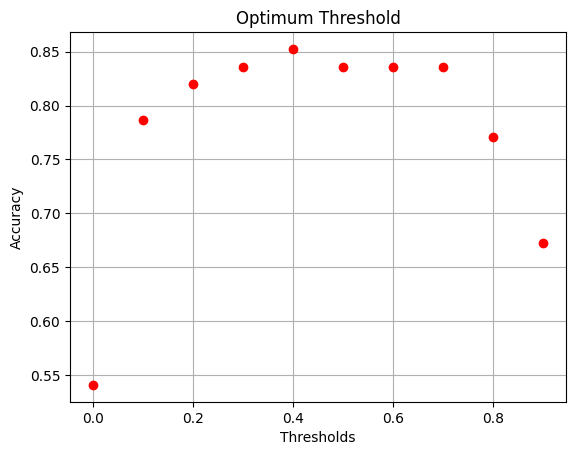

In [ ]:
plt.plot(threshold, accuracy_list, marker='o', linestyle='', color='red', label='Scatter Plot')
plt.title("Optimum Threshold")
plt.xlabel("Thresholds")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

# 6) Sklearn LR Model

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test)
y_pred

array([0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0])

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {round(accuracy,2)}")

accuracy: 0.84


In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[22,  6],
       [ 4, 29]])

In [ ]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.79      0.81        28
           1       0.83      0.88      0.85        33

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



roc auc score:  0.895021645021645


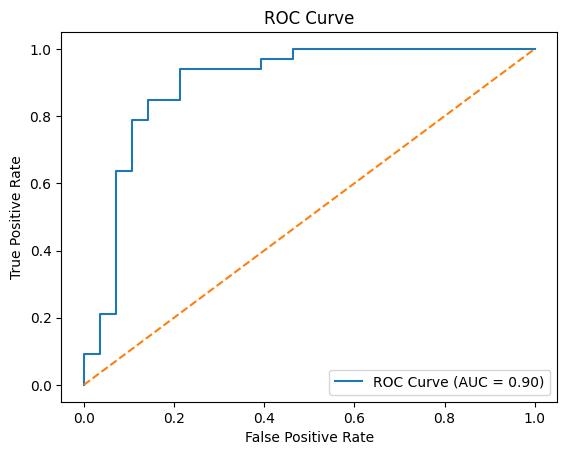

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)
print('roc auc score: ', roc_auc)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## 7. Results and Model Comparison

### Model Performance

Two Logistic Regression models were implemented and evaluated on the Heart Disease dataset:

- **Logistic Regression from Scratch:** Implemented using the sigmoid activation function, binary cross-entropy loss, and gradient descent.
- **Scikit-learn Logistic Regression:** Implemented using `sklearn.linear_model.LogisticRegression`.

Both models achieved the same classification results on the test set.

| Metric | From Scratch | Scikit-learn |
|---|---:|---:|
| Accuracy | 0.84 | 0.84 |
| Precision (Class 1) | 0.83 | 0.83 |
| Recall (Class 1) | 0.88 | 0.88 |
| F1-score (Class 1) | 0.85 | 0.85 |
| ROC-AUC | 0.8918 | 0.8950 |

### Confusion Matrix

Both models produced the same confusion matrix:

\[
\begin{bmatrix}
22 & 6 \\
4 & 29
\end{bmatrix}
\]

The models correctly classified 22 samples from class 0 and 29 samples from class 1. They also produced 6 false positives and 4 false negatives.

### ROC-AUC Comparison

The Scikit-learn model achieved a slightly higher ROC-AUC score (0.8950) than the scratch implementation (0.8918). However, the difference is very small.

Although both models produced identical class predictions at the default threshold of 0.5, their predicted probabilities were slightly different, resulting in different ROC-AUC scores.

### Threshold Analysis

The threshold analysis showed that a threshold of 0.4 achieved the highest accuracy on the test set, approximately 85.25%, compared with 83.61% at the default threshold of 0.5.

However, since this threshold was selected using test-set results, it should be considered exploratory. In a more rigorous evaluation, threshold selection should be performed using a separate validation set.

### Conclusion

The results indicate that the Logistic Regression model implemented from scratch performs very similarly to the Scikit-learn implementation.

This exercise provided an opportunity to understand the internal mechanism of Logistic Regression, including the sigmoid function, binary cross-entropy loss, gradient descent, and threshold-based classification.

Overall, both implementations achieved comparable performance on this dataset, while the scratch implementation helped demonstrate how the algorithm works internally.